# German Credit Risk Analysis

## Overview:
This project explores the German Credit dataset to investigate patterns associated with customer credit-worthiness. The analysis includes data preparation, anonymisation techniques, descriptive statistics, and visual exploration of borrower characteristics.

### Data Loading

In [1]:
import pandas as pd
gc=pd.read_csv("Credit.csv")

### Initial Data Inspection

In [2]:
print(gc.head(10))

   Unnamed: 0  Default checkingstatus1  duration   history       purpose  \
0           1        0            <DM0         6  terrible  goods/repair   
1           2        1         DM0-200        48      poor  goods/repair   
2           3        0       NoAccount        12  terrible           edu   
3           4        0            <DM0        42      poor  goods/repair   
4           5        1            <DM0        24      poor        newcar   
5           6        0       NoAccount        36      poor           edu   
6           7        0       NoAccount        24      poor  goods/repair   
7           8        0         DM0-200        36      poor       usedcar   
8           9        0       NoAccount        12      poor  goods/repair   
9          10        1         DM0-200        30  terrible        newcar   

   amount     savings      employ  installment     sex  residence  age  \
0    1169     DM0-100     7+years            4    male          4   67   
1    5951     D

### Dataset Overview

In [3]:
gc.shape
gc.dtypes
gc.nunique()

Unnamed: 0         1000
Default               2
checkingstatus1       4
duration             33
history               3
purpose               5
amount              921
savings               3
employ                4
installment           4
sex                   2
residence             4
age                  53
housing               3
cards                 4
liable                2
tele                  2
foreign               2
dtype: int64

### Loan Purpose Generalisation

In [4]:
gc["purpose"].value_counts()

purpose
goods/repair    495
newcar          234
biz             109
usedcar         103
edu              59
Name: count, dtype: int64

In [5]:
gc.purpose = gc.purpose.replace(['newcar', 'usedcar'], 'car')
gc.purpose = gc.purpose.replace(['goods/repair', 'biz', 'edu'], 'non-car')
gc["purpose"].value_counts()


purpose
non-car    663
car        337
Name: count, dtype: int64

### Descriptive Statistics and Distribution Analysis

In [6]:
gc.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,1000.0,500.500,288.819436,1.0,250.75,500.5,750.25,1000.0
Default,1000.0,0.300,0.458487,0.0,0.00,0.0,1.00,1.0
duration,1000.0,20.903,12.058814,4.0,12.00,18.0,24.00,72.0
amount,1000.0,3271.258,2822.736876,250.0,1365.50,2319.5,3972.25,18424.0
installment,1000.0,2.973,1.118715,1.0,2.00,3.0,4.00,4.0
residence,1000.0,2.845,1.103718,1.0,2.00,3.0,4.00,4.0
age,1000.0,35.546,11.375469,19.0,27.00,33.0,42.00,75.0
cards,1000.0,1.407,0.577654,1.0,1.00,1.0,2.00,4.0
liable,1000.0,1.155,0.362086,1.0,1.00,1.0,1.00,2.0


array([[<Axes: title={'center': 'Unnamed: 0'}>,
        <Axes: title={'center': 'Default'}>,
        <Axes: title={'center': 'duration'}>],
       [<Axes: title={'center': 'amount'}>,
        <Axes: title={'center': 'installment'}>,
        <Axes: title={'center': 'residence'}>],
       [<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'cards'}>,
        <Axes: title={'center': 'liable'}>]], dtype=object)

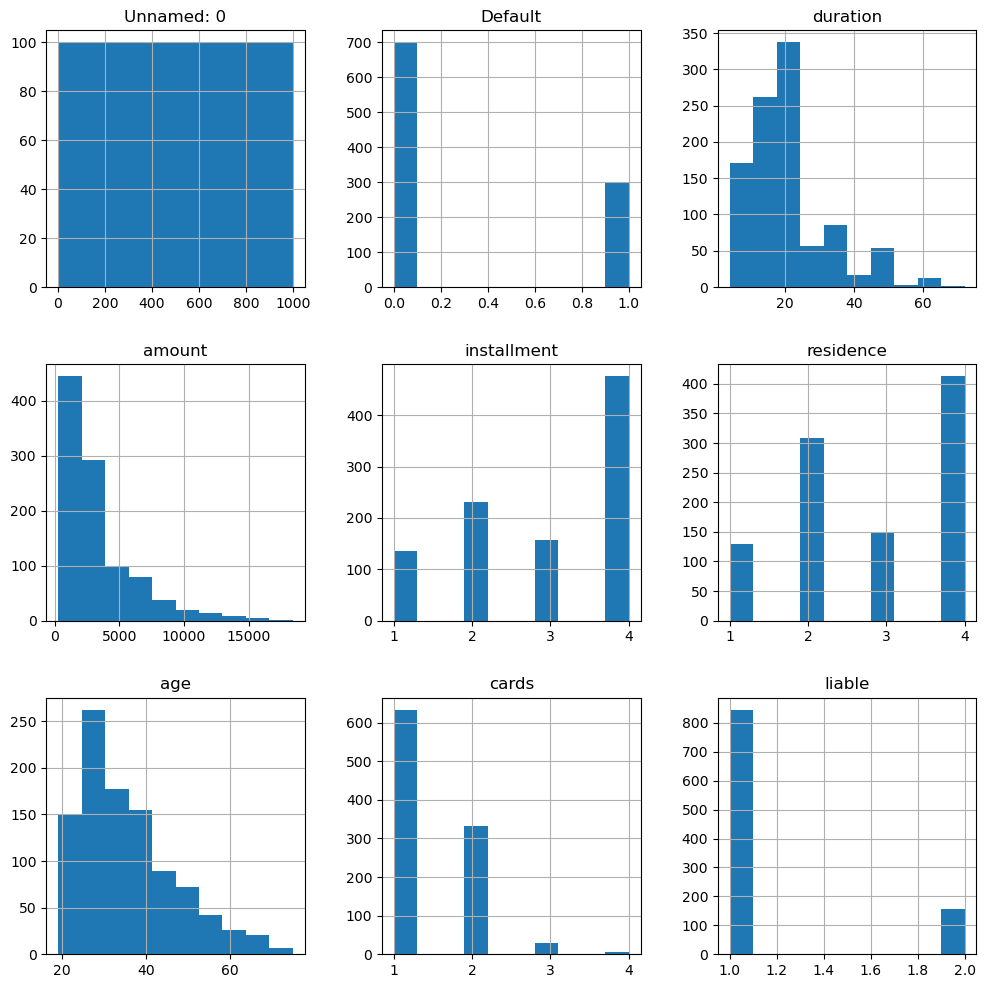

In [7]:
gc.hist(figsize=(12,12))

### Age Generalisation

In [8]:
ageBins = [0, 20, 30, 40, 50, 60, 100]
ageLabels = ['under20', '21-30', '31-40', '41-50', '51-60', 'over 60']
gc['age'] = pd.cut(gc['age'], bins=ageBins, labels=ageLabels)
print(gc.head())

   Unnamed: 0  Default checkingstatus1  duration   history  purpose  amount  \
0           1        0            <DM0         6  terrible  non-car    1169   
1           2        1         DM0-200        48      poor  non-car    5951   
2           3        0       NoAccount        12  terrible  non-car    2096   
3           4        0            <DM0        42      poor  non-car    7882   
4           5        1            <DM0        24      poor      car    4870   

   savings    employ  installment     sex  residence      age  housing  cards  \
0  DM0-100   7+years            4    male          4  over 60      own      2   
1  DM0-100  1-7years            2  female          2    21-30      own      1   
2  DM0-100  1-7years            2    male          3    41-50      own      1   
3  DM0-100  1-7years            2    male          4    41-50  forfree      1   
4  DM0-100  1-7years            3    male          4    51-60  forfree      2   

   liable tele  foreign  
0       1  y

array([[<Axes: title={'center': 'Unnamed: 0'}>,
        <Axes: title={'center': 'Default'}>,
        <Axes: title={'center': 'duration'}>],
       [<Axes: title={'center': 'amount'}>,
        <Axes: title={'center': 'installment'}>,
        <Axes: title={'center': 'residence'}>],
       [<Axes: title={'center': 'cards'}>,
        <Axes: title={'center': 'liable'}>, <Axes: >]], dtype=object)

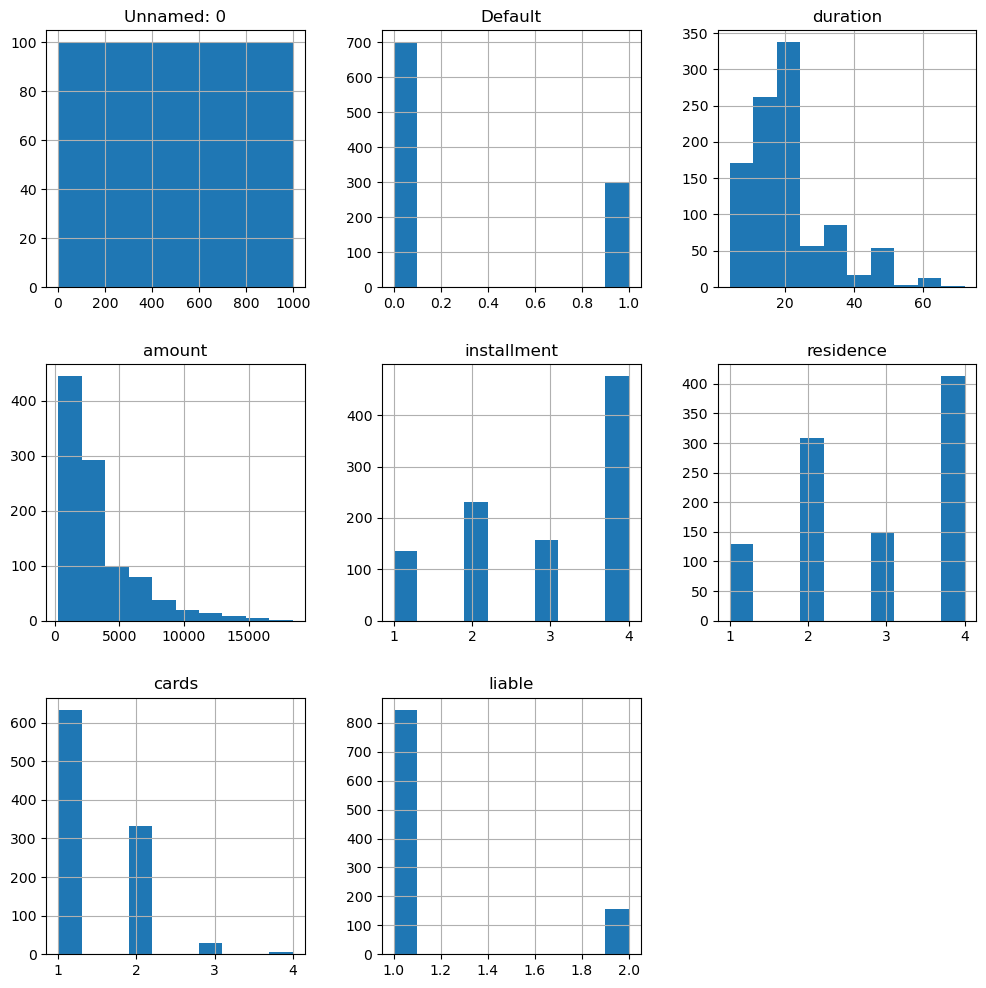

In [9]:
gc.hist(figsize=(12,12))

<Axes: xlabel='age'>

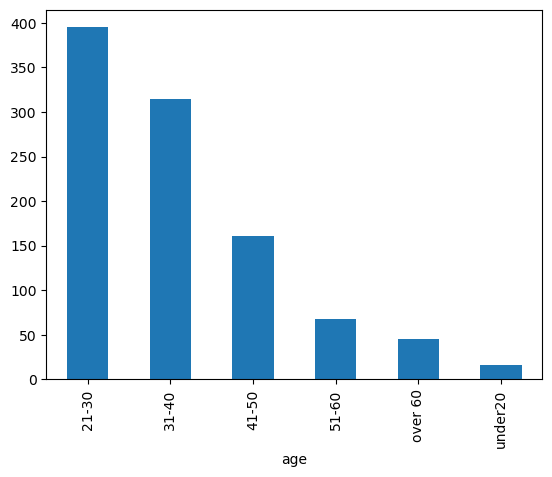

In [10]:
gc["age"].value_counts().plot(kind="bar")

### Sex Distribution of Applicants

<Axes: xlabel='sex'>

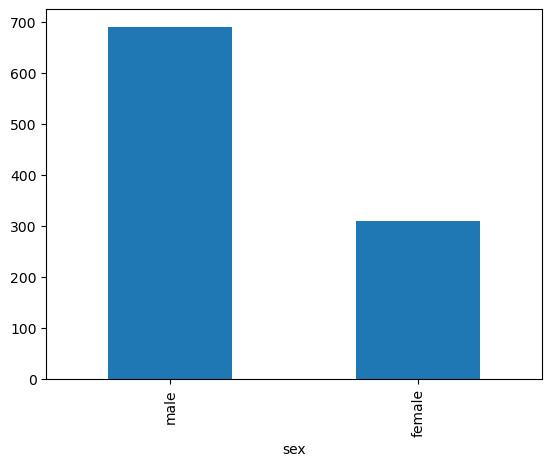

In [11]:
gc["sex"].value_counts().plot(kind="bar")

### Sensitive Attribute Suppression

In [12]:
gc=gc.drop(columns=["sex"])

### Exporting the Anonymised Dataset

In [13]:
gc.to_csv("AnonCredit.csv")

### Validation of Anonymisation Results

In [14]:
print(gc.head(10))

   Unnamed: 0  Default checkingstatus1  duration   history  purpose  amount  \
0           1        0            <DM0         6  terrible  non-car    1169   
1           2        1         DM0-200        48      poor  non-car    5951   
2           3        0       NoAccount        12  terrible  non-car    2096   
3           4        0            <DM0        42      poor  non-car    7882   
4           5        1            <DM0        24      poor      car    4870   
5           6        0       NoAccount        36      poor  non-car    9055   
6           7        0       NoAccount        24      poor  non-car    2835   
7           8        0         DM0-200        36      poor      car    6948   
8           9        0       NoAccount        12      poor  non-car    3059   
9          10        1         DM0-200        30  terrible      car    5234   

      savings      employ  installment  residence      age  housing  cards  \
0     DM0-100     7+years            4          4  o

In [15]:
gc.nunique()

Unnamed: 0         1000
Default               2
checkingstatus1       4
duration             33
history               3
purpose               2
amount              921
savings               3
employ                4
installment           4
residence             4
age                   6
housing               3
cards                 4
liable                2
tele                  2
foreign               2
dtype: int64

### Exploratory Analysis of the Anonymised Dataset

In [16]:
cd=pd.read_csv("Credit.csv")
result = pd.merge(gc, cd[['Unnamed: 0','sex']], on='Unnamed: 0')
print(result.head(10))

   Unnamed: 0  Default checkingstatus1  duration   history  purpose  amount  \
0           1        0            <DM0         6  terrible  non-car    1169   
1           2        1         DM0-200        48      poor  non-car    5951   
2           3        0       NoAccount        12  terrible  non-car    2096   
3           4        0            <DM0        42      poor  non-car    7882   
4           5        1            <DM0        24      poor      car    4870   
5           6        0       NoAccount        36      poor  non-car    9055   
6           7        0       NoAccount        24      poor  non-car    2835   
7           8        0         DM0-200        36      poor      car    6948   
8           9        0       NoAccount        12      poor  non-car    3059   
9          10        1         DM0-200        30  terrible      car    5234   

      savings      employ  installment  residence      age  housing  cards  \
0     DM0-100     7+years            4          4  o

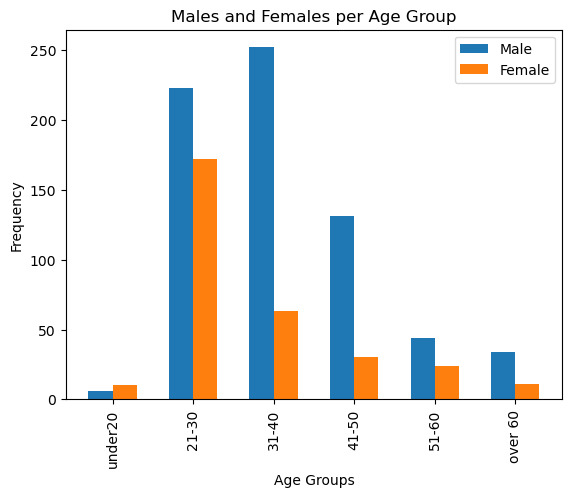

In [17]:
import numpy as np
import matplotlib.pyplot as plt
ages = ['under20','21-30','31-40','41-50','51-60','over 60']
ageSex_counts = result.groupby(['age','sex'], observed = True).size().unstack(fill_value = 0).reindex(ages)

ageGroups = ageSex_counts.index
m_counts = ageSex_counts['male']
f_counts = ageSex_counts['female']

ind = np.arange(len(ages))
width =0.3

plt.figure()
plt.bar(ind-width/2, m_counts, width, label='Male')
plt.bar(ind+width/2, f_counts, width, label='Female')

plt.xlabel ('Age Groups')
plt.ylabel ('Frequency')
plt.xticks(ind, ageGroups, rotation = 90)
plt.title('Males and Females per Age Group')
plt.legend()
plt.show()


In [18]:
result["sex"].value_counts

<bound method IndexOpsMixin.value_counts of 0        male
1      female
2        male
3        male
4        male
        ...  
995    female
996      male
997      male
998      male
999      male
Name: sex, Length: 1000, dtype: object>

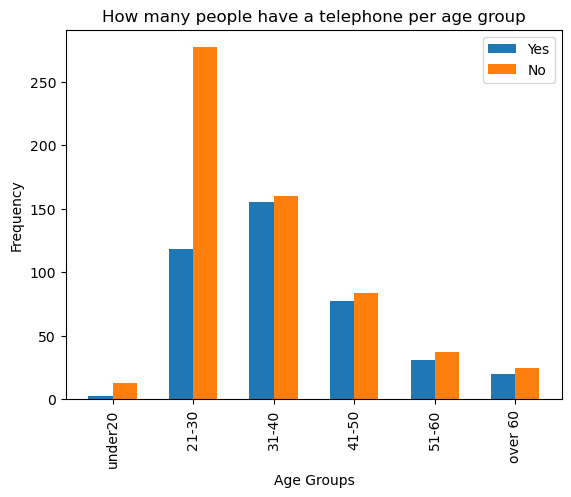

In [19]:
ageTele_counts = result.groupby(['age','tele'], observed = True).size().unstack(fill_value = 0).reindex(ages)

ageGroups1 = ageTele_counts.index
y_counts = ageTele_counts['yes']
n_counts = ageTele_counts['no']

ind = np.arange(len(ages))
width =0.3

plt.figure()
plt.bar(ind-width/2, y_counts, width, label='Yes')
plt.bar(ind+width/2, n_counts, width, label='No')

plt.xlabel ('Age Groups')
plt.ylabel ('Frequency')
plt.xticks(ind, ageGroups1, rotation = 90)
plt.title('How many people have a telephone per age group')
plt.legend()
plt.show()

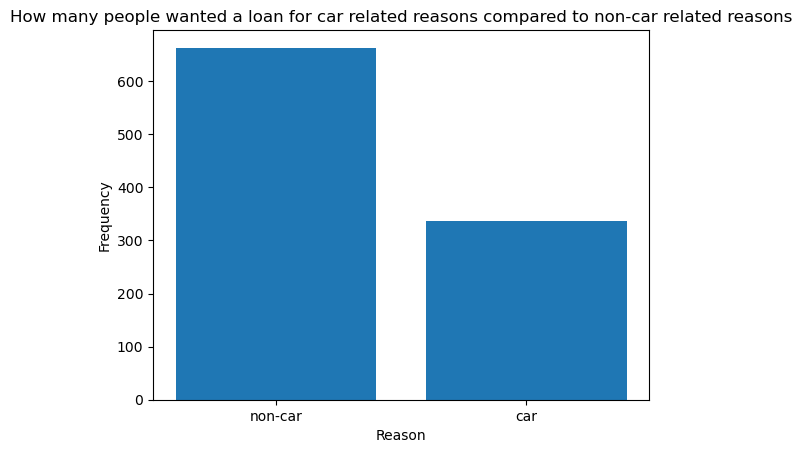

In [20]:
reason = result['purpose'].value_counts()
plt.bar(reason.index, reason)
plt.xlabel ('Reason')
plt.ylabel ('Frequency')
plt.title ('How many people wanted a loan for car related reasons compared to non-car related reasons')
plt.show()

In [21]:
result=result.drop(columns=["purpose"])

cd1=pd.read_csv("Credit.csv")
gc_final = pd.merge(result, cd1[['Unnamed: 0','purpose']], on='Unnamed: 0')
print(gc_final.head(10))

   Unnamed: 0  Default checkingstatus1  duration   history  amount  \
0           1        0            <DM0         6  terrible    1169   
1           2        1         DM0-200        48      poor    5951   
2           3        0       NoAccount        12  terrible    2096   
3           4        0            <DM0        42      poor    7882   
4           5        1            <DM0        24      poor    4870   
5           6        0       NoAccount        36      poor    9055   
6           7        0       NoAccount        24      poor    2835   
7           8        0         DM0-200        36      poor    6948   
8           9        0       NoAccount        12      poor    3059   
9          10        1         DM0-200        30  terrible    5234   

      savings      employ  installment  residence      age  housing  cards  \
0     DM0-100     7+years            4          4  over 60      own      2   
1     DM0-100    1-7years            2          2    21-30      own      

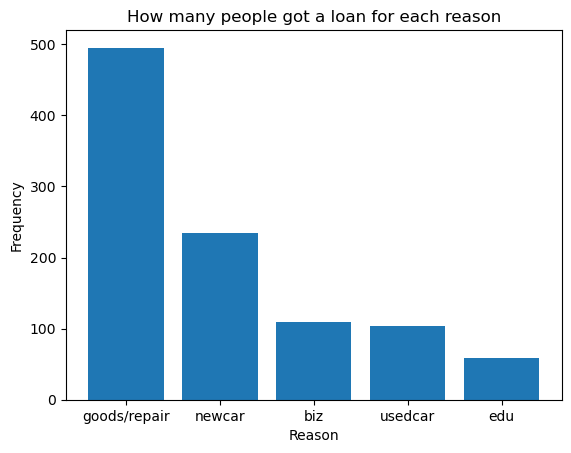

In [22]:
reason = gc_final['purpose'].value_counts()
plt.bar(reason.index, reason)
plt.xlabel ('Reason')
plt.ylabel ('Frequency')
plt.title ('How many people got a loan for each reason')
plt.show()